Verified global optimum: (0, 1, 2)
Global minimum cost: 54

OPTIMAL SOLUTION FOUND BY ACO
--------------------------------
Facility 1 -> Location 1
Facility 2 -> Location 2
Facility 3 -> Location 3
Minimum Cost: 54


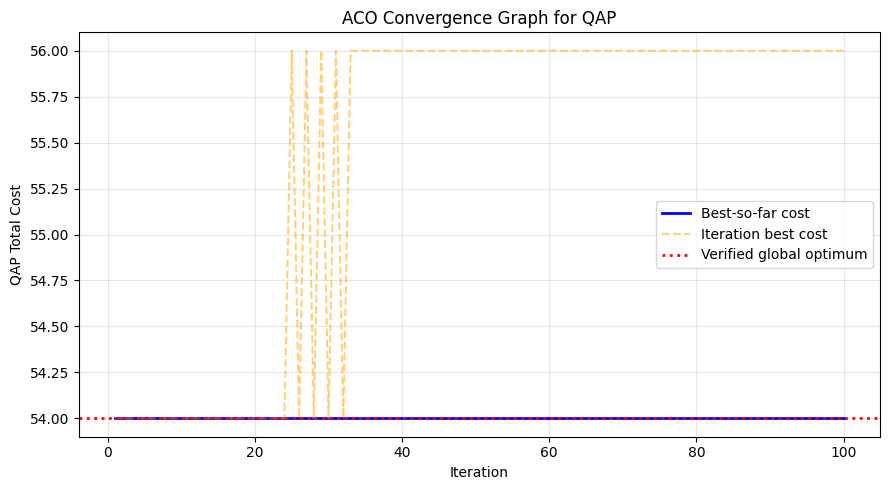

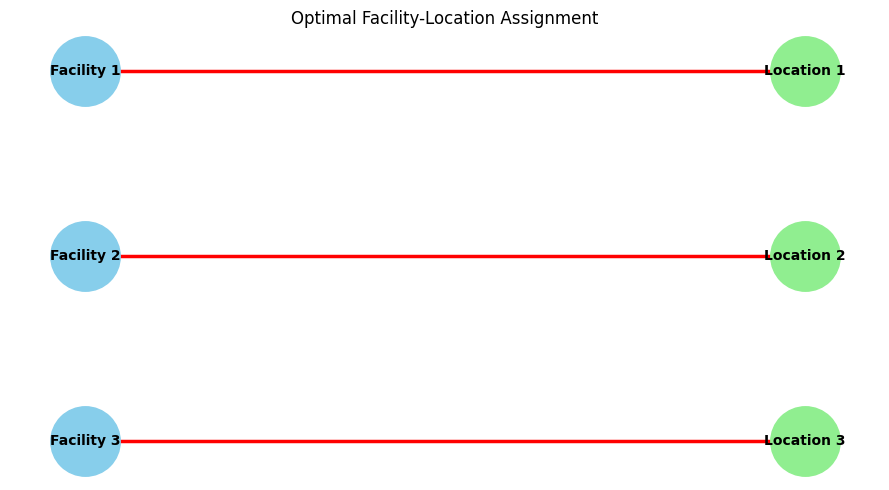

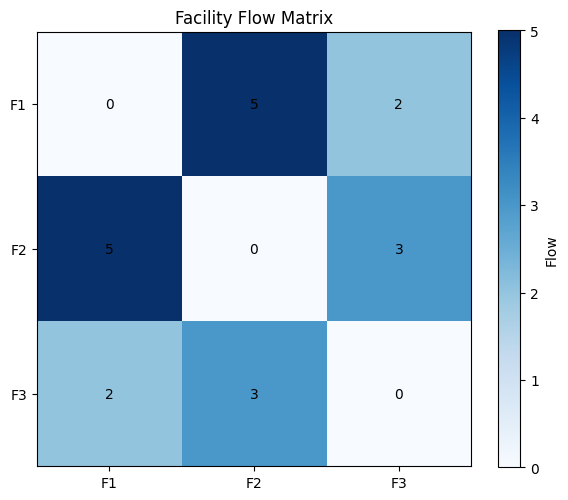

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

# ---------------------------------------
# 1. QAP OBJECTIVE FUNCTION
# ---------------------------------------

def qap_cost(solution, flow, distance):
    n = len(solution)
    cost = 0

    for i in range(n):
        for j in range(n):
            cost += (
                flow[i][j] *
                distance[solution[i]][solution[j]]
            )

    return cost


# ---------------------------------------
# 2. ACO ALGORITHM FOR QAP
# ---------------------------------------

def aco_qap(flow, distance, ants=20,
            iterations=100, alpha=1,
            beta=2, rho=0.5, Q=100):

    n = len(flow)

    pheromone = np.ones((n, n))

    best_solution = None
    best_cost = float('inf')

    convergence = []
    iteration_best = []

    for iteration in range(iterations):

        solutions = []
        costs = []

        for ant in range(ants):

            solution = [-1] * n
            available = list(range(n))

            for i in range(n):

                probabilities = []

                for k in available:

                    delta = 0

                    for j in range(i):
                        delta += (
                            flow[i][j] *
                            distance[k][solution[j]]
                            +
                            flow[j][i] *
                            distance[solution[j]][k]
                        )

                    eta = 1 / (delta + 1e-10)

                    value = (
                        pheromone[i][k] ** alpha
                        * eta ** beta
                    )

                    probabilities.append(value)

                probabilities = np.array(probabilities)
                probabilities /= probabilities.sum()

                selected = np.random.choice(
                    len(available),
                    p=probabilities
                )

                location = available.pop(selected)
                solution[i] = location

            cost = qap_cost(solution, flow, distance)

            solutions.append(solution)
            costs.append(cost)

            if cost < best_cost:
                best_cost = cost
                best_solution = solution.copy()

        iteration_best.append(min(costs))

        # Track best-so-far cost
        convergence.append(best_cost)

        # Evaporation
        pheromone *= (1 - rho)

        # Deposit pheromone
        for solution, cost in zip(solutions, costs):

            for i in range(n):
                pheromone[i][solution[i]] += Q / cost

    return (
        best_solution,
        best_cost,
        convergence,
        iteration_best
    )


# ---------------------------------------
# 3. INPUT DATA
# ---------------------------------------

flow = np.array([
    [0, 5, 2],
    [5, 0, 3],
    [2, 3, 0]
])

distance = np.array([
    [0, 2, 4],
    [2, 0, 3],
    [4, 3, 0]
])

from itertools import permutations

# Verify the global optimum using exhaustive search
all_solutions = list(permutations(range(len(flow))))

optimal_solution = min(
    all_solutions,
    key=lambda s: qap_cost(s, flow, distance)
)

optimal_cost = qap_cost(
    optimal_solution, flow, distance
)

print("Verified global optimum:", optimal_solution)
print("Global minimum cost:", optimal_cost)



# ---------------------------------------
# 4. RUN ACO
# ---------------------------------------

np.random.seed(42)

best_solution, best_cost, convergence, iteration_best = (
    aco_qap(
        flow,
        distance,
        ants=20,
        iterations=100,
        alpha=1,
        beta=2,
        rho=0.5,
        Q=100
    )
)

print("\nOPTIMAL SOLUTION FOUND BY ACO")
print("--------------------------------")

for i, location in enumerate(best_solution):
    print(f"Facility {i+1} -> Location {location+1}")

print("Minimum Cost:", best_cost)


# ---------------------------------------
# 5. GRAPH 1: CONVERGENCE GRAPH
# ---------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(convergence)+1),
    convergence,
    color='blue',
    linewidth=2,
    label='Best-so-far cost'
)

plt.plot(
    range(1, len(iteration_best)+1),
    iteration_best,
    color='orange',
    alpha=0.5,
    linestyle='--',
    label='Iteration best cost'
)

plt.xlabel("Iteration")
plt.ylabel("QAP Total Cost")
plt.title("ACO Convergence Graph for QAP")
plt.axhline(
    y=optimal_cost,
    color='red',
    linestyle=':',
    linewidth=2,
    label='Verified global optimum'
)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# ---------------------------------------
# 6. GRAPH 2: FACILITY-LOCATION DIAGRAM
# ---------------------------------------

G = nx.Graph()

facilities = [
    f"Facility {i+1}" for i in range(len(flow))
]

locations = [
    f"Location {i+1}" for i in range(len(flow))
]

G.add_nodes_from(facilities, bipartite=0)
G.add_nodes_from(locations, bipartite=1)

for i, location in enumerate(best_solution):
    G.add_edge(
        facilities[i],
        locations[location]
    )

pos = {}

for i, facility in enumerate(facilities):
    pos[facility] = (0, -i)

for i, location in enumerate(locations):
    pos[location] = (2, -i)

plt.figure(figsize=(9, 5))

nx.draw_networkx_nodes(
    G, pos,
    nodelist=facilities,
    node_color='skyblue',
    node_size=2500
)

nx.draw_networkx_nodes(
    G, pos,
    nodelist=locations,
    node_color='lightgreen',
    node_size=2500
)

nx.draw_networkx_edges(
    G, pos,
    width=2.5,
    edge_color='red'
)

nx.draw_networkx_labels(
    G, pos,
    font_size=10,
    font_weight='bold'
)

plt.title("Optimal Facility-Location Assignment")
plt.axis('off')
plt.tight_layout()
plt.show()


# ---------------------------------------
# 7. GRAPH 3: FLOW MATRIX HEATMAP
# ---------------------------------------

plt.figure(figsize=(6, 5))

plt.imshow(flow, cmap='Blues')

plt.colorbar(label='Flow')

plt.xticks(range(len(flow)),
           [f'F{i+1}' for i in range(len(flow))])

plt.yticks(range(len(flow)),
           [f'F{i+1}' for i in range(len(flow))])

plt.title("Facility Flow Matrix")

for i in range(len(flow)):
    for j in range(len(flow)):
        plt.text(
            j, i,
            flow[i][j],
            ha='center',
            va='center'
        )

plt.tight_layout()
plt.show()
